# Clustering

En el notebook anterior utilizamos PCA para reducir la dimensionalidad de un conjunto de datos formado por casos semanales de dengue en las entidades federativas de México.

Ahora abordaremos un problema diferente: **¿Existen semanas que presenten patrones similares de dengue entre las entidades?**

Para responder esta pregunta utilizaremos técnicas de **clustering**.

El clustering es un método de aprendizaje no supervisado cuyo objetivo es dividir un conjunto de observaciones en grupos o **clusters**.

A diferencia de un problema de clasificación, aquí no conocemos previamente las etiquetas de los grupos.

Cada semana puede representarse mediante un vector:

$$
\mathbf{x}_t=
(x_{t1},x_{t2},\ldots,x_{tp}),
$$

donde

$$
p=32
$$

corresponde al número de entidades federativas.

Dos semanas serán consideradas similares si sus vectores presentan valores cercanos de acuerdo con alguna medida de distancia.

En este notebook estudiaremos:

1. distancia entre observaciones;
2. algoritmo $k$-means;
3. elección del número de clusters;
4. interpretación de los grupos obtenidos;
5. representación de los clusters utilizando PCA.

El objetivo no será asignar categorías conocidas, sino **descubrir estructuras presentes en los datos**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from scipy.spatial.distance import euclidean
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

In [2]:
ruta = "https://raw.githubusercontent.com/jamc88/TSMA-II-26-O/refs/heads/main/Datos/casos_semanales_dengue_2020_2026.csv"

datos = pd.read_csv(ruta, parse_dates=["FECHA"])
datos = datos.sort_values("FECHA").reset_index(drop=True)


# Variables correspondientes a las entidades
estados = [
    columna
    for columna in datos.columns
    if columna != "FECHA"]


X = datos[estados].copy()
X

,AGUASCALIENTES,BAJA CALIFORNIA,BAJA CALIFORNIA SUR,CAMPECHE,CHIAPAS,CHIHUAHUA,COAHUILA,COLIMA,DISTRITO FEDERAL,DURANGO,...,QUINTANA ROO,SAN LUIS POTOSI,SINALOA,SONORA,TABASCO,TAMAULIPAS,TLAXCALA,VERACRUZ,YUCATAN,ZACATECAS
0,0,1,0,5,2,0,1,2,1,0,...,24,0,5,0,16,5,0,41,12,0
1,0,1,1,5,12,1,1,4,2,0,...,33,0,12,2,21,6,0,69,10,0
2,0,0,0,2,14,0,0,10,1,0,...,35,0,3,0,22,3,0,87,19,0
3,0,0,1,7,8,0,0,2,0,0,...,28,0,11,1,30,10,0,66,21,0
4,0,0,0,2,8,0,0,4,0,0,...,19,1,4,0,26,9,0,58,14,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
329,0,0,4,1,4,0,0,0,0,0,...,3,0,11,27,16,3,0,15,0,0
330,0,0,6,0,9,0,0,0,0,0,...,4,0,14,38,14,0,0,13,0,0
331,0,0,8,1,3,0,0,0,1,0,...,4,1,16,50,8,1,0,7,1,0
332,0,0,5,0,4,0,0,0,0,0,...,4,0,13,34,10,0,0,0,0,0


In [3]:
# Estandarización
scaler = StandardScaler()

X_std = scaler.fit_transform(X)

X_std = pd.DataFrame(X_std,columns=estados,index=datos.index)
X_std

,AGUASCALIENTES,BAJA CALIFORNIA,BAJA CALIFORNIA SUR,CAMPECHE,CHIAPAS,CHIHUAHUA,COAHUILA,COLIMA,DISTRITO FEDERAL,DURANGO,...,QUINTANA ROO,SAN LUIS POTOSI,SINALOA,SONORA,TABASCO,TAMAULIPAS,TLAXCALA,VERACRUZ,YUCATAN,ZACATECAS
0,-0.240981,0.034278,-0.420341,-0.111745,-0.576140,-0.198041,-0.347373,-0.364908,-0.189939,-0.237416,...,0.070445,-0.512840,-0.383701,-0.371489,-0.223662,-0.309717,-0.24454,-0.262206,-0.169766,-0.24554
1,-0.240981,0.034278,-0.387033,-0.111745,-0.369270,-0.015318,-0.347373,-0.322068,0.083508,-0.237416,...,0.284340,-0.512840,-0.276342,-0.341119,-0.111596,-0.282973,-0.24454,-0.051558,-0.184874,-0.24554
2,-0.240981,-0.347352,-0.420341,-0.218078,-0.327896,-0.198041,-0.360666,-0.193549,-0.189939,-0.237416,...,0.331872,-0.512840,-0.414375,-0.371489,-0.089183,-0.363204,-0.24454,0.083858,-0.116886,-0.24554
3,-0.240981,-0.347352,-0.387033,-0.040856,-0.452018,-0.198041,-0.360666,-0.364908,-0.463386,-0.237416,...,0.165509,-0.512840,-0.291679,-0.356304,0.090122,-0.175997,-0.24454,-0.074128,-0.101778,-0.24554
4,-0.240981,-0.347352,-0.420341,-0.218078,-0.452018,-0.198041,-0.360666,-0.322068,-0.463386,-0.237416,...,-0.048386,-0.485595,-0.399038,-0.371489,0.000470,-0.202741,-0.24454,-0.134313,-0.154657,-0.24554
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
329,-0.240981,-0.347352,-0.287108,-0.253522,-0.534766,-0.198041,-0.360666,-0.407748,-0.463386,-0.237416,...,-0.428645,-0.512840,-0.291679,0.038508,-0.223662,-0.363204,-0.24454,-0.457808,-0.260416,-0.24554
330,-0.240981,-0.347352,-0.220492,-0.288966,-0.431331,-0.198041,-0.360666,-0.407748,-0.463386,-0.237416,...,-0.404879,-0.512840,-0.245668,0.205544,-0.268488,-0.443436,-0.24454,-0.472854,-0.260416,-0.24554
331,-0.240981,-0.347352,-0.153876,-0.253522,-0.555453,-0.198041,-0.360666,-0.407748,-0.189939,-0.237416,...,-0.404879,-0.485595,-0.214994,0.387766,-0.402967,-0.416692,-0.24454,-0.517993,-0.252862,-0.24554
332,-0.240981,-0.347352,-0.253800,-0.288966,-0.534766,-0.198041,-0.360666,-0.407748,-0.463386,-0.237416,...,-0.404879,-0.512840,-0.261005,0.144804,-0.358140,-0.443436,-0.24454,-0.570655,-0.260416,-0.24554


## ¿Cómo medimos la similitud entre dos semanas?

Para formar grupos necesitamos una manera de medir qué tan parecidas son dos observaciones.

Una de las medidas más utilizadas es la **distancia euclidiana**.

Si tenemos dos semanas $\mathbf{x}_i=(x_{i1},x_{i2},\ldots,x_{ip})$ y $\mathbf{x}_j=(x_{j1},x_{j2},\ldots,x_{jp}),$ su distancia euclidiana es

$$
d(\mathbf{x}_i,\mathbf{x}_j)
=\sqrt{\sum_{k=1}^{p}(x_{ik}-x_{jk})^2}.
$$

En nuestro caso, $p=32,$ por lo que la distancia compara simultáneamente el comportamiento del dengue en las 32 entidades.

Una distancia pequeña indica que las dos semanas presentan patrones similares.

Una distancia grande indica que sus configuraciones entre entidades son diferentes.



### ¿Por qué estandarizamos antes?

La distancia euclidiana depende directamente de la escala de las variables.

Si una entidad presenta una variabilidad mucho mayor que las demás, podría dominar la distancia.

Por ello utilizaremos las variables estandarizadas:

$$
Z_j=
\frac{X_j-\bar X_j}{s_j}.
$$

De esta manera, todas las entidades participan en una escala comparable.

In [4]:
# tres semanas de ejemplo
indices = [0,1,200]


for i in indices: print(i,datos.loc[i, "FECHA"].date())


# Distancias utilizando variables estandarizadas
d_01 = euclidean(X_std.iloc[0],X_std.iloc[1])

d_0_200 = euclidean(X_std.iloc[0],X_std.iloc[200])

d_1_200 = euclidean(X_std.iloc[1],X_std.iloc[200])


print("\nDistancias:")
print(f"Semana 0 vs semana 1: "f"{d_01:.3f}")
print(f"Semana 0 vs semana 200: "f"{d_0_200:.3f}")
print(f"Semana 1 vs semana 200: "f"{d_1_200:.3f}")

0 2020-01-05
1 2020-01-12
200 2023-11-05

Distancias:
Semana 0 vs semana 1: 0.604
Semana 0 vs semana 200: 7.956
Semana 1 vs semana 200: 7.717



Las semanas del 5 y 12 de enero de 2020 presentan una distancia euclidiana de

$$
d=0.604.
$$

Esto indica que sus patrones de casos de dengue entre las 32 entidades son relativamente similares.

En cambio, la semana del 5 de noviembre de 2023 presenta distancias mucho mayores:
$d(\text{05-01-2020},\text{05-11-2023})=7.956,$ y $d(\text{12-01-2020},\text{05-11-2023})=7.717.$

Por tanto, el patrón multivariado observado en noviembre de 2023 es considerablemente diferente al observado durante las primeras semanas de 2020.

Es importante observar que la distancia no mide qué tan separadas están las semanas en el tiempo.

Mide qué tan diferentes son sus vectores:

$$
(Z_1,Z_2,\ldots,Z_{32}).
$$

Dos semanas muy alejadas temporalmente podrían tener una distancia pequeña si presentan patrones similares entre las entidades.

De manera inversa, dos semanas cercanas en el calendario pueden tener una distancia grande si el patrón epidemiológico cambia considerablemente.

## Clustering mediante $k$-means

El algoritmo $k$-means busca dividir las observaciones en $k$ grupos.

Cada grupo se representa mediante un punto denominado **centroide**.

Si el cluster $C_j$ contiene varias observaciones, su centroide es el vector promedio:

$$
\boldsymbol{\mu}_j
=
\frac{1}{|C_j|}
\sum_{\mathbf{x}_i\in C_j}
\mathbf{x}_i.
$$

En nuestro caso, cada centroide contiene $32$ valores y representa el patrón promedio de dengue de las semanas pertenecientes a ese grupo.


### ¿Cómo funciona $k$-means?

El algoritmo repite dos pasos principales:

1. Asigna cada observación al centroide más cercano.
2. Recalcula cada centroide utilizando la media de las observaciones asignadas.

Este procedimiento se repite hasta que las asignaciones dejan de cambiar significativamente.

El objetivo es minimizar la suma de las distancias cuadráticas de cada observación respecto al centroide de su grupo:

$$
\operatorname{Inercia}
=
\sum_{j=1}^{k}
\sum_{\mathbf{x}_i\in C_j}
\left\|
\mathbf{x}_i-\boldsymbol{\mu}_j
\right\|^2.
$$

Por tanto, $k$-means intenta construir clusters que sean internamente compactos.



### El número de clusters

El valor de $k$ debe establecerse antes de ejecutar el algoritmo.

Por ejemplo,

$$
k=3
$$

obliga al algoritmo a dividir las 334 semanas en tres grupos.

Esto no significa que tres sea necesariamente el número correcto de clusters.

Primero utilizaremos $k=3$ como ejemplo y posteriormente estudiaremos cómo seleccionar un valor adecuado de $k$.

### Ejemplo del funcionamiento de $k$-means

La siguiente figura muestra de manera esquemática cómo funciona el algoritmo $k$-means.

Supongamos que queremos dividir las observaciones en

$$
k=3
$$

clusters.

El procedimiento puede entenderse mediante cuatro pasos.

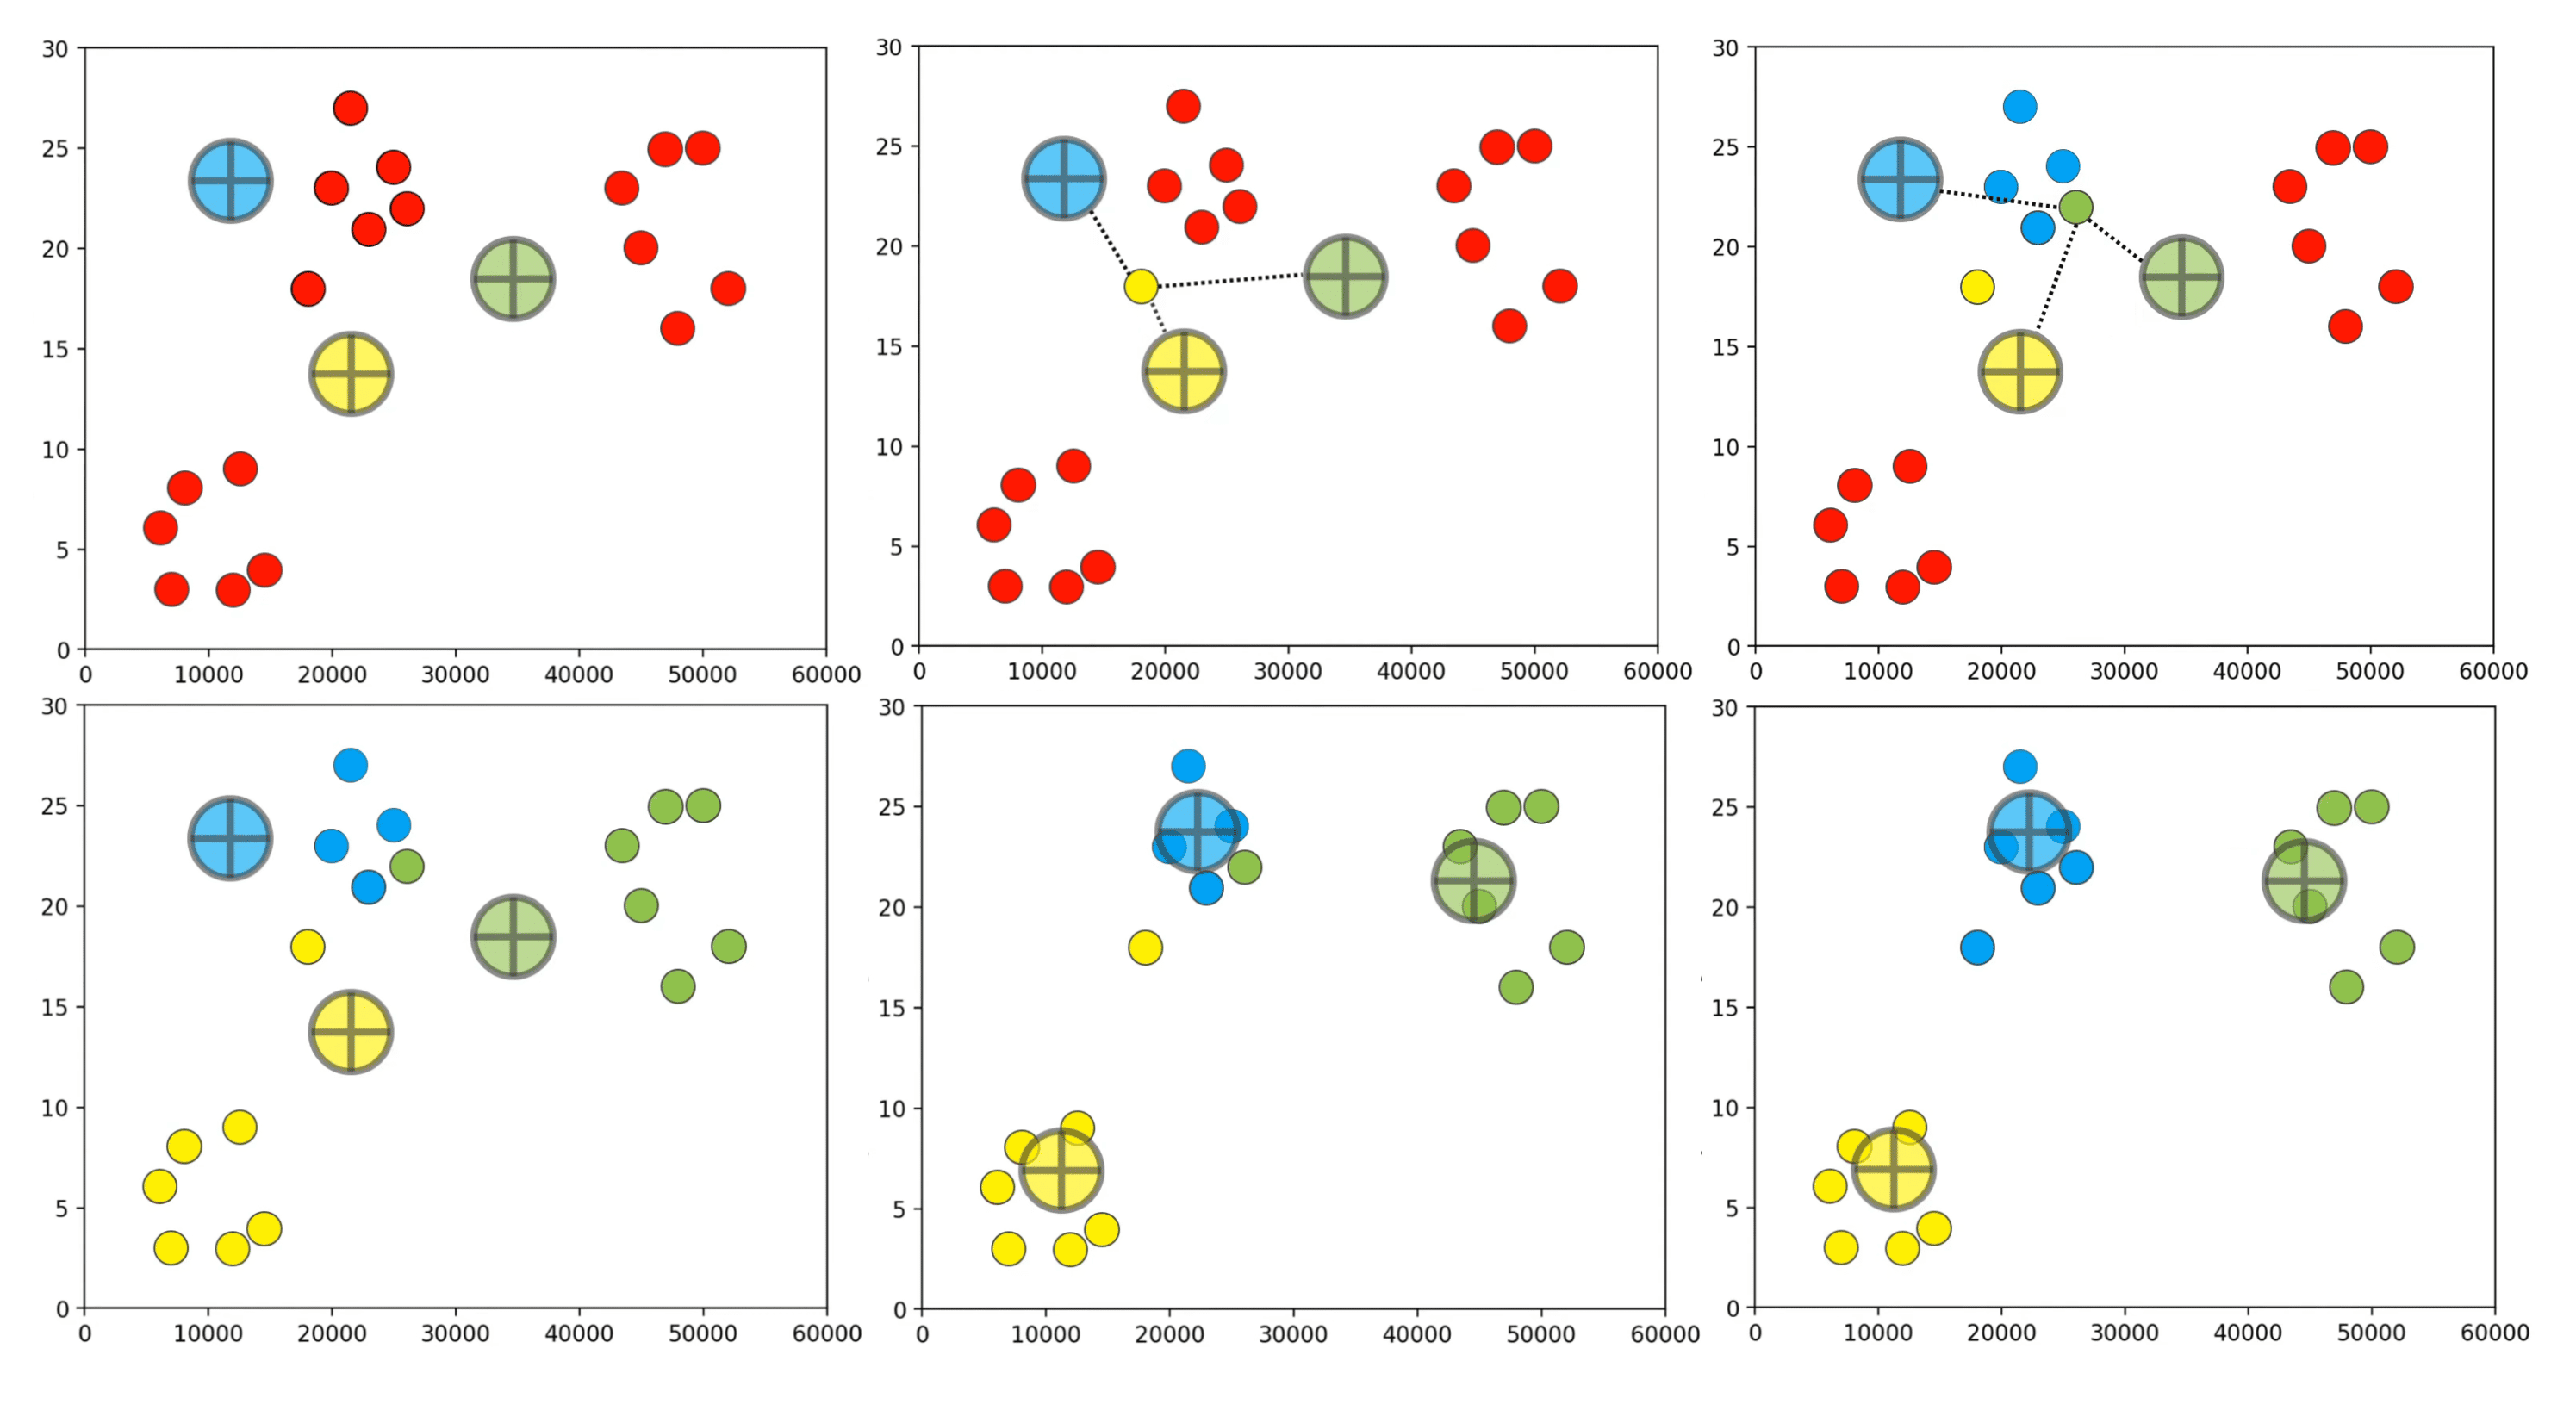

**Importante:** en la figura los puntos se representan en dos dimensiones para facilitar la visualización. En nuestro análisis, cada punto representa una semana descrita por **32 variables estandarizadas**, por lo que el algoritmo $k$-means trabaja realmente en un espacio de dimensión $32$.

#### 1. Inicialización

Primero se seleccionan $k$ centroides iniciales.

En la figura aparecen tres centroides, representados mediante símbolos grandes de distintos colores.

En esta primera etapa los centroides todavía no representan necesariamente la estructura real de los datos.



#### 2. Asignación

Para cada observación se calcula su distancia a los centroides.

Cada punto se asigna al cluster cuyo centroide se encuentre más cercano:

$$
C(\mathbf{x}_i)
=
\arg\min_j
d(\mathbf{x}_i,\boldsymbol{\mu}_j).
$$

Utilizando distancia euclidiana:

$$
d(\mathbf{x}_i,\boldsymbol{\mu}_j)
=
\sqrt{
\sum_{r=1}^{p}
(x_{ir}-\mu_{jr})^2
}.
$$

En la figura, los puntos cambian de color según el centroide al que fueron asignados.



#### 3. Actualización de los centroides

Una vez asignados los puntos, cada centroide se vuelve a calcular como el promedio de las observaciones de su cluster:

$$
\boldsymbol{\mu}_j
=
\frac{1}{|C_j|}
\sum_{\mathbf{x}_i\in C_j}
\mathbf{x}_i.
$$

Por esta razón, los centroides se desplazan hacia el centro de los grupos de observaciones que les fueron asignados.



#### 4. Repetición

Después de actualizar los centroides, las observaciones vuelven a asignarse al centroide más cercano.

El proceso

$$
\boxed{
\text{asignar}
\rightarrow
\text{actualizar}
\rightarrow
\text{asignar}
\rightarrow
\text{actualizar}
}
$$

se repite hasta que los centroides prácticamente dejan de cambiar.

El resultado final es una partición de los datos en $k$ grupos internamente compactos.


En nuestro ejemplo de dengue, el dibujo debe interpretarse conceptualmente de la misma manera, aunque nuestras observaciones no tienen solamente dos coordenadas.

Cada semana está representada por un vector de $32$ componentes:

$$
\mathbf{x}_t
=
(Z_{t1},Z_{t2},\ldots,Z_{t,32}).
$$

Por tanto, los centroides también son vectores de dimensión $32$.

La figura en dos dimensiones sirve para visualizar el procedimiento, pero $k$-means puede realizar exactamente el mismo proceso en espacios de dimensión mucho mayor.

* **`KMeans()`**
Configura el modelo de Machine Learning (K-Means).
* `n_clusters=3`: Le indica al algoritmo que debe encontrar 3 grupos distintos.
* `random_state=42`: Establece una "semilla" aleatoria para que, al ejecutar el código nuevamente, obtengamos exactamente los mismos resultados.
* `n_init=50`: Le dice al modelo que intente inicializar los centros de los clústeres 50 veces distintas de forma aleatoria y se quede con el mejor resultado.

* **`.fit_predict(X_std)`**
Ejecuta el modelo sobre los datos estandarizados (`X_std`).



In [5]:
# ejemplo: k = 3
kmeans_3 = KMeans(n_clusters=3, random_state=42, n_init=50)

clusters_3 = kmeans_3.fit_predict(X_std)

# Guardamos la asignación
resultado_clusters = pd.DataFrame({
    "FECHA": datos["FECHA"],
    "cluster": clusters_3})

# Tamaño de los clusters
tamano_clusters = resultado_clusters["cluster"].value_counts().sort_index()

print("Número de semanas por cluster:")
display(tamano_clusters.to_frame("numero_semanas"))

print("\nInercia:",round(kmeans_3.inertia_,2))

Número de semanas por cluster:


,numero_semanas
cluster,
0,289
1,16
2,29



Inercia: 4670.88


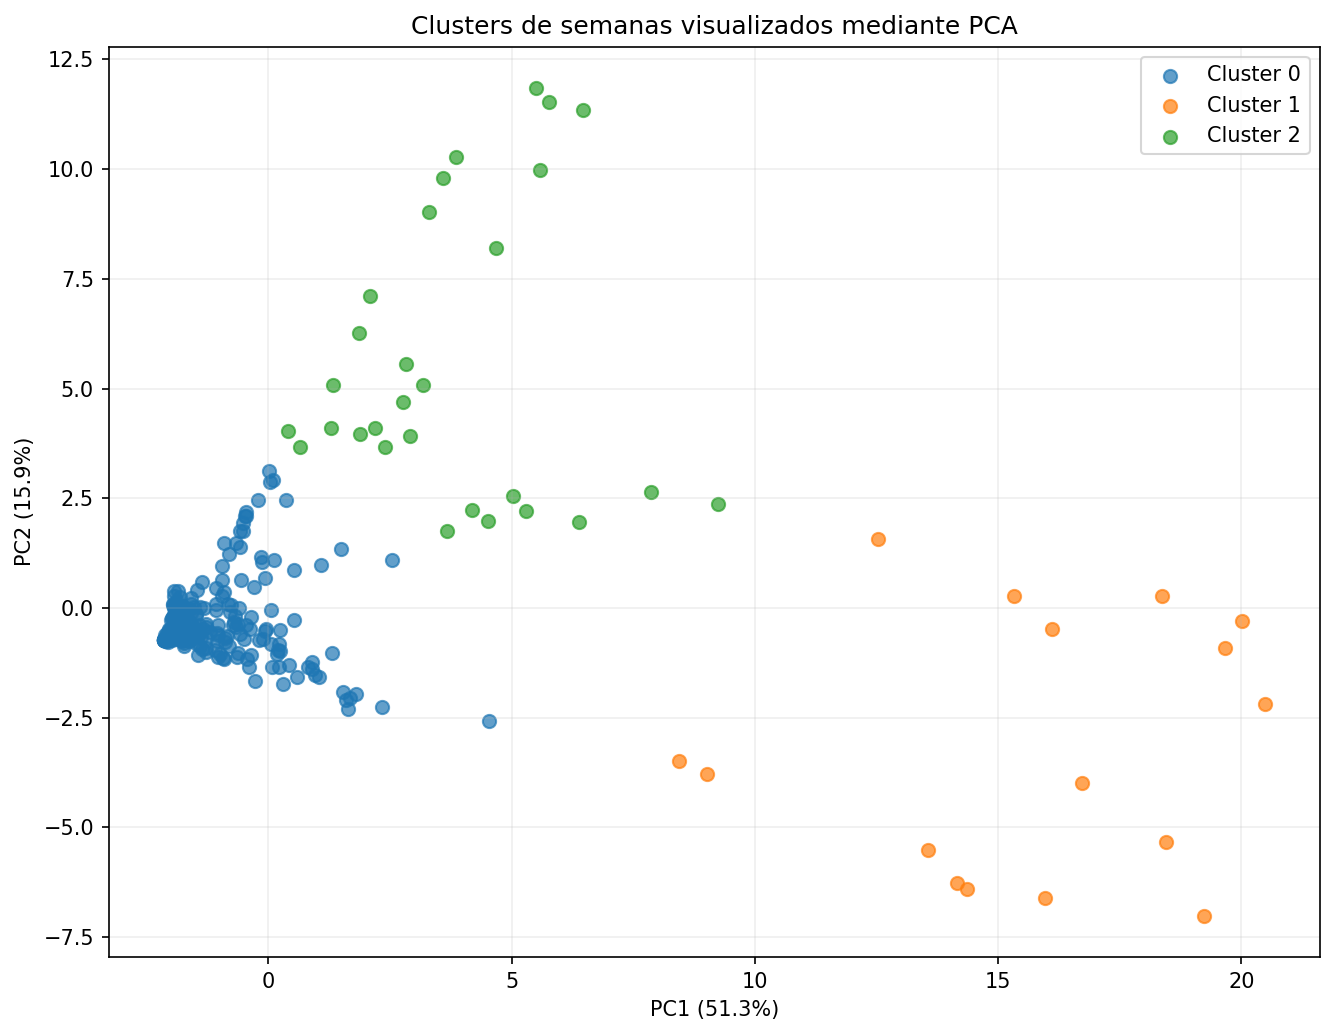

In [6]:
# PCA para visualización

pca_visual = PCA(n_components=2)

X_pca = pca_visual.fit_transform(X_std)


fig, ax = plt.subplots(figsize=(9, 7), dpi=150)

for cluster in sorted(np.unique(clusters_3)):

    mascara = (clusters_3 == cluster)

    ax.scatter(
        X_pca[mascara, 0],
        X_pca[mascara, 1],
        s=40,
        alpha=0.7,
        label=f"Cluster {cluster}")

ax.set_title("Clusters de semanas visualizados mediante PCA")
ax.set_xlabel(f"PC1 "f"({pca_visual.explained_variance_ratio_[0]*100:.1f}%)")
ax.set_ylabel(f"PC2 "f"({pca_visual.explained_variance_ratio_[1]*100:.1f}%)")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

Al utilizar $k=3,$ el algoritmo $k$-means produjo grupos de tamaños muy diferentes:

$$
\begin{array}{c|c}
\text{Cluster} & \text{Número de semanas}\\
\hline
0 & 289\\
1 & 16\\
2 & 29
\end{array}
$$

El cluster 0 contiene la mayor parte de las semanas, mientras que los clusters 1 y 2 agrupan episodios menos frecuentes.

En la representación mediante PCA se observa que:

- el **cluster 0** se concentra principalmente cerca del origen;
- el **cluster 1** aparece asociado con valores elevados de $PC_1$;
- el **cluster 2** aparece asociado principalmente con valores elevados de $PC_2$.

Esto sugiere que los clusters podrían estar distinguiendo diferentes regímenes multivariados de actividad del dengue.

Sin embargo, esta gráfica utiliza únicamente

$$
PC_1
\quad\text{y}\quad
PC_2,
$$

que explican conjuntamente aproximadamente

$$
67.2\%
$$

de la variabilidad.

El algoritmo $k$-means fue aplicado utilizando las $32$ variables estandarizadas.

Por tanto, la gráfica PCA debe interpretarse únicamente como una **visualización bidimensional de una partición obtenida en 32 dimensiones**.

## ¿Cómo elegir el número de clusters?

El algoritmo $k$-means requiere especificar previamente el número de grupos: $k.$

Si elegimos un valor muy pequeño de $k$, podemos juntar observaciones que en realidad presentan comportamientos diferentes.

Si elegimos un valor demasiado grande, podemos dividir artificialmente grupos que deberían permanecer juntos.

Una primera herramienta para estudiar este problema es el **método del codo**.


### Inercia

$k$-means intenta minimizar la suma de las distancias cuadráticas entre cada observación y el centroide de su cluster:

$$
\operatorname{Inercia}(k)
=
\sum_{j=1}^{k}
\sum_{\mathbf{x}_i\in C_j}
\left\|
\mathbf{x}_i-\boldsymbol{\mu}_j
\right\|^2.
$$

Al aumentar $k$, la inercia siempre disminuye.

En el caso extremo, $k=n,$ cada observación podría formar su propio cluster y la inercia sería cero.

Por tanto, no buscamos simplemente el valor de $k$ con menor inercia.

Buscamos un punto a partir del cual aumentar el número de clusters produzca mejoras cada vez menores.

Este cambio de comportamiento se conoce como el **codo** de la curva.

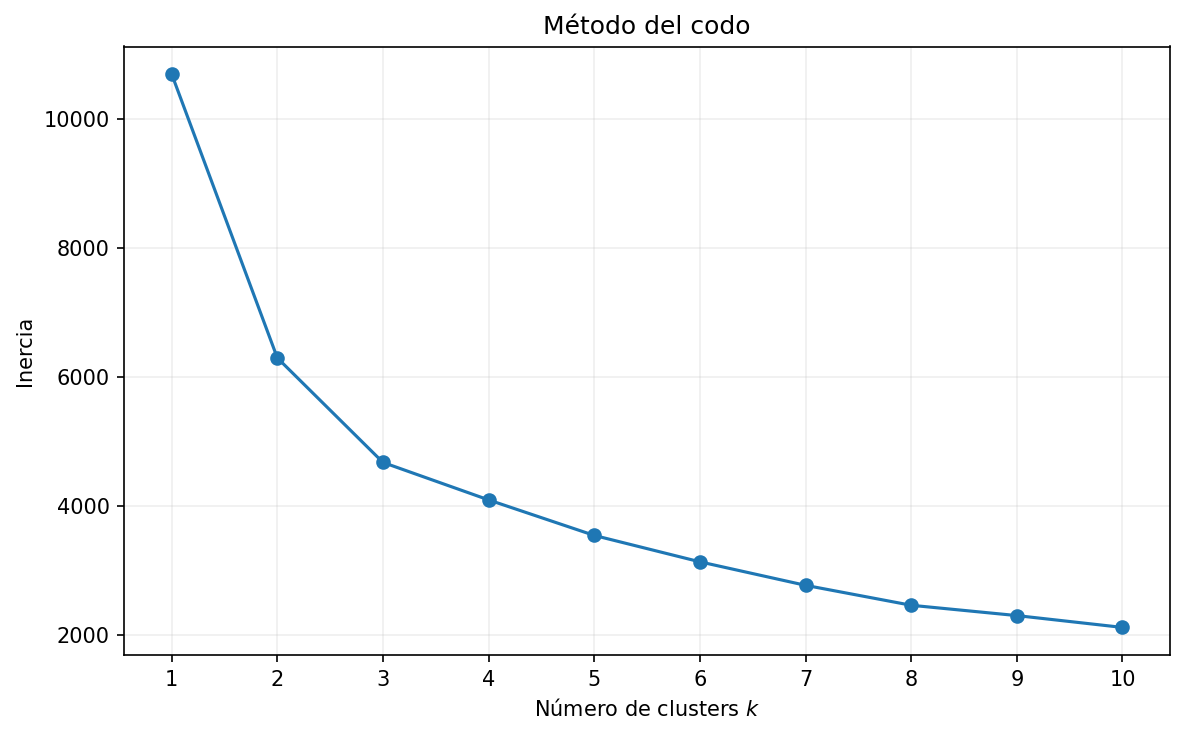

In [7]:
# Método del codo

valores_k = range(1,11)

inercias = []

for k in valores_k:

    modelo = KMeans(n_clusters=k, random_state=42, n_init=50)

    modelo.fit(X_std)

    inercias.append(modelo.inertia_)


fig, ax = plt.subplots(figsize=(8, 5), dpi=150)

ax.plot(list(valores_k),inercias,marker="o",linewidth=1.5)

ax.set_title("Método del codo")
ax.set_xlabel("Número de clusters $k$")
ax.set_ylabel("Inercia")
ax.set_xticks(list(valores_k))
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

## Índice de silueta

Otra forma de evaluar la calidad de un clustering es el **índice de silueta**.

Para una observación $i$ definimos:

- $a(i)$: distancia promedio entre $i$ y las demás observaciones de su mismo cluster;
- $b(i)$: menor distancia promedio entre $i$ y las observaciones de cualquier otro cluster.

El coeficiente de silueta es

$$
s(i)
=
\frac{
b(i)-a(i)
}{
\max\{a(i),b(i)\}
}.
$$

Sus valores se encuentran entre

$$
-1
\leq
s(i)
\leq
1.
$$

En términos generales:

- valores cercanos a $1$ indican observaciones bien asignadas;
- valores cercanos a $0$ indican observaciones cercanas a la frontera entre clusters;
- valores negativos pueden indicar una asignación poco adecuada.

El promedio de los coeficientes de silueta permite comparar diferentes valores de $k$.

A diferencia de la inercia, aquí buscamos valores **altos**.

In [8]:
# Índice de silueta

valores_k_sil = range(2,11)

siluetas = []


for k in valores_k_sil:

    modelo = KMeans(n_clusters=k, random_state=42, n_init=50)

    etiquetas = modelo.fit_predict(X_std)

    score = silhouette_score(X_std,etiquetas)

    siluetas.append(score)



resultados_k = pd.DataFrame({
    "k": list(valores_k_sil),
    "silhouette": siluetas})

resultados_k.round(3)

,k,silhouette
0,2,0.747
1,3,0.641
2,4,0.649
3,5,0.640
4,6,0.580
5,7,0.538
6,8,0.538
7,9,0.543
8,10,0.544


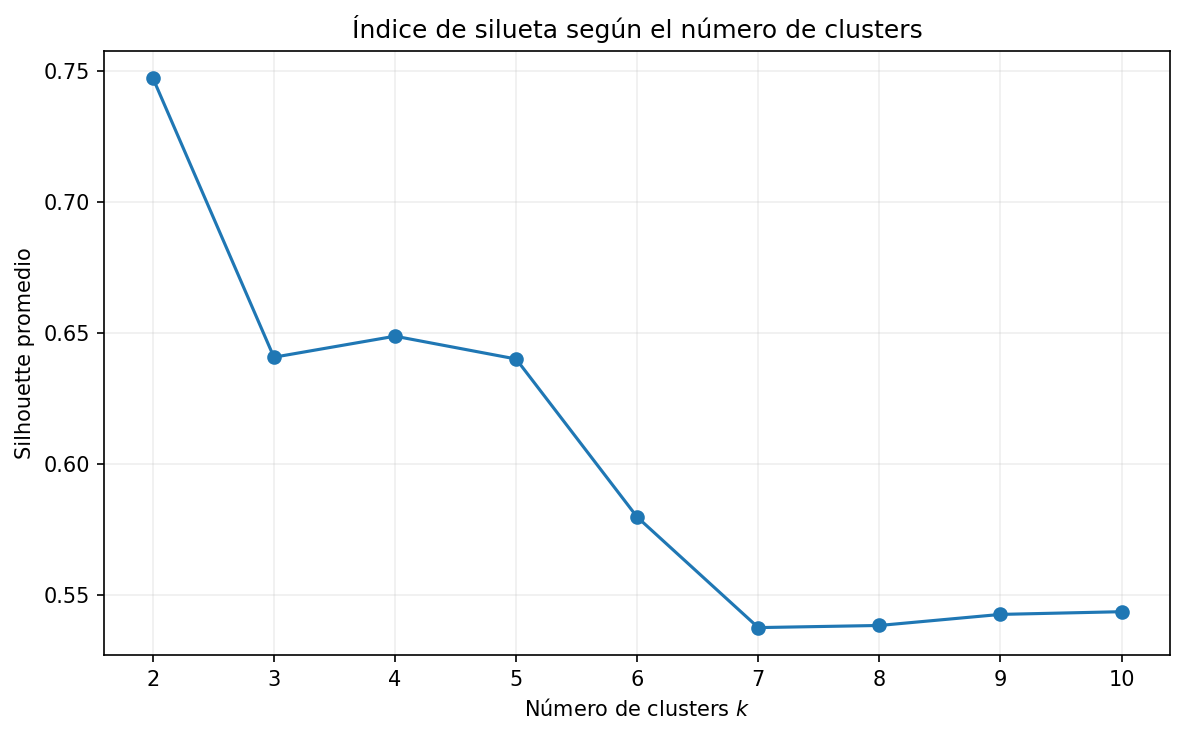

In [9]:
fig, ax = plt.subplots(figsize=(8, 5), dpi=150)

ax.plot(
    resultados_k["k"],
    resultados_k["silhouette"],
    marker="o",
    linewidth=1.5)

ax.set_title("Índice de silueta según el número de clusters")
ax.set_xlabel("Número de clusters $k$")
ax.set_ylabel("Silhouette promedio")
ax.set_xticks(resultados_k["k"])
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

### Selección del número de clusters

El método del codo muestra una disminución muy fuerte de la inercia al pasar de $k=1$
a $k=2,$ y una reducción adicional importante al pasar a $k=3.$

A partir de ese punto, las mejoras son progresivamente menores.

Por tanto, la gráfica sugiere que una solución con aproximadamente

$$
k=2
\quad\text{o}\quad
k=3
$$

puede describir razonablemente la estructura de los datos.

El índice de silueta proporciona una evidencia más clara.

Obtuvimos:

$$
s(2)=0.747,
$$

$$
s(3)=0.641,
$$

$$
s(4)=0.649.
$$

El mayor valor corresponde a

$$
\boxed{k=2}.
$$

Esto indica que, entre las soluciones evaluadas, la partición en dos clusters presenta la mejor combinación entre:

- similitud de las observaciones dentro de cada cluster;
- separación entre clusters diferentes.

Por tanto, utilizaremos

$$
\boxed{k=2}
$$

como solución principal.

Sin embargo, debe recordarse que en clustering no existe necesariamente un único valor ``correcto'' de $k$.

Una solución con más clusters puede proporcionar una descripción más detallada de la estructura de los datos, aunque presente una menor separación global.

In [10]:
# Solución : k = 2

kmeans_2 = KMeans(n_clusters=2, random_state=42, n_init=50)

clusters_2 = kmeans_2.fit_predict(X_std)

resultado_clusters["cluster_k2"] = (clusters_2)


# Tamaño de los clusters

tamano_k2 = resultado_clusters["cluster_k2"].value_counts().sort_index()

display(tamano_k2.to_frame("numero_semanas"))
print("Silhouette:",round(silhouette_score(X_std,clusters_2),3))

,numero_semanas
cluster_k2,
0,317
1,17


Silhouette: 0.747


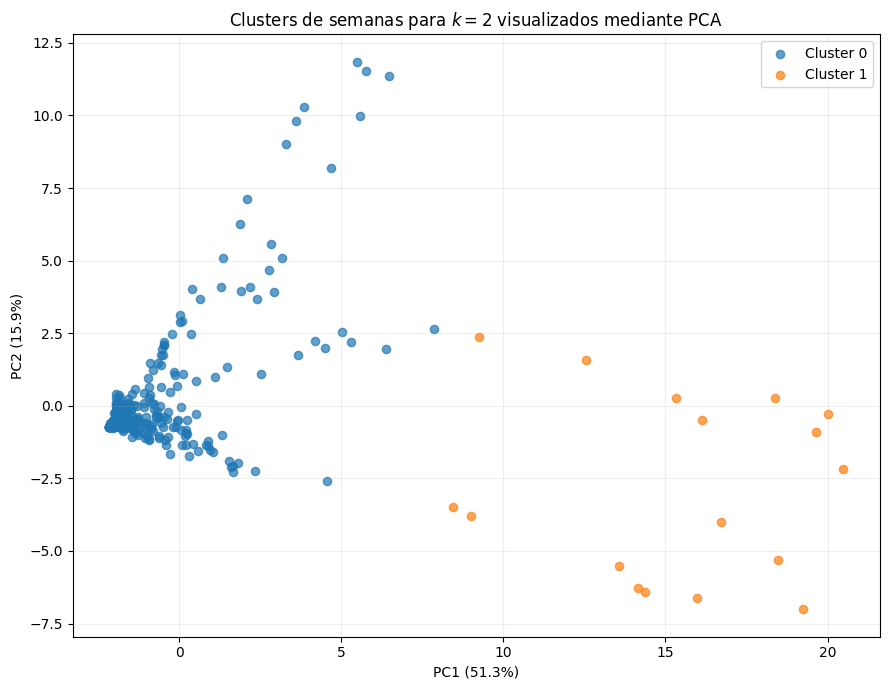

In [11]:
fig, ax = plt.subplots(figsize=(9, 7))

for cluster in sorted(np.unique(clusters_2)):

    mascara = (clusters_2 == cluster)

    ax.scatter(
        X_pca[mascara, 0],
        X_pca[mascara, 1],
        s=35,
        alpha=0.7,
        label=f"Cluster {cluster}")

ax.set_title("Clusters de semanas para $k=2$ visualizados mediante PCA")
ax.set_xlabel("PC1 (51.3%)")
ax.set_ylabel("PC2 (15.9%)")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

La solución seleccionada produjo dos clusters de tamaños muy diferentes:

$$
\begin{array}{c|c}
\text{Cluster} & \text{Número de semanas}\\
\hline
0 & 317\\
1 & 17
\end{array}
$$

El cluster 0 contiene aproximadamente el $94.9\%$ de las semanas, mientras que el cluster 1 contiene únicamente alrededor del $5.1\%.$

En la representación mediante PCA se observa que el cluster 1 se concentra principalmente en semanas con valores muy elevados de $PC_1$.

Como anteriormente encontramos que $PC_1$ está fuertemente relacionado con la intensidad general del dengue, este resultado sugiere que el cluster 1 podría representar semanas de actividad epidemiológica excepcionalmente alta.

En cambio, el cluster 0 contiene la mayor parte de las semanas con niveles más cercanos al comportamiento habitual.

El índice de silueta obtenido fue $0.747,$ lo que indica una separación relativamente clara entre ambos grupos.

Sin embargo, las etiquetas 0 y 1 son arbitrarias.

Por ello, antes de asignar una interpretación definitiva debemos caracterizar los clusters utilizando las variables originales.

In [12]:
# Casos totales por semana

resultado_clusters["casos_totales"] = datos[estados].sum(axis=1).values

# Resumen por cluster

resumen_clusters = (
    resultado_clusters
    .groupby("cluster_k2")
    .agg(
        numero_semanas=("FECHA","size"),
        casos_media=("casos_totales","mean"),
        casos_mediana=("casos_totales","median"),
        casos_minimo=("casos_totales","min"),
        casos_maximo=("casos_totales","max")
    ))

resumen_clusters.round(1)

,numero_semanas,casos_media,casos_mediana,casos_minimo,casos_maximo
cluster_k2,,,,,
0,317,490.5,209.0,0,3618
1,17,5147.5,5424.0,3040,6480


In [13]:
# Semanas del cluster menos frecuente

cluster_pequeno = tamano_k2.idxmin()

semanas_cluster_pequeno = (
    resultado_clusters[resultado_clusters["cluster_k2"] == cluster_pequeno]
    .sort_values("FECHA")
)

semanas_cluster_pequeno[["FECHA","casos_totales"]]

,FECHA,casos_totales
239,2024-08-04,3040
240,2024-08-11,4000
241,2024-08-18,4708
242,2024-08-25,5789
243,2024-09-01,6330
244,2024-09-08,6300
245,2024-09-15,5424
246,2024-09-22,6480
247,2024-09-29,5595
248,2024-10-06,5718


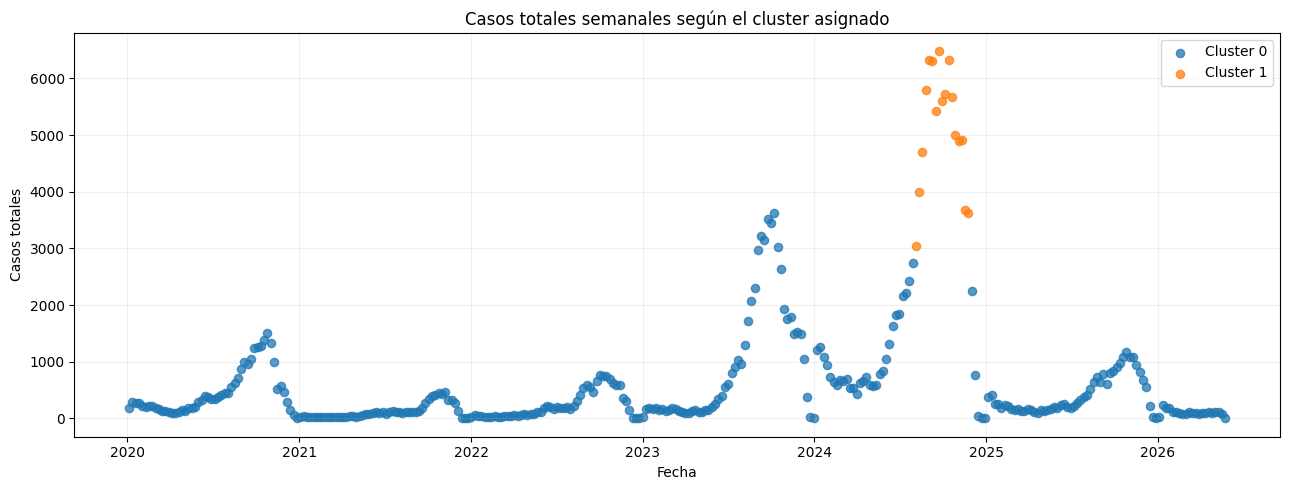

In [14]:
# Casos totales semanales coloreados por cluster

fig, ax = plt.subplots(figsize=(13, 5))


for cluster in sorted(resultado_clusters["cluster_k2"].unique()):

    mascara = (resultado_clusters["cluster_k2"] == cluster)

    ax.scatter(
        resultado_clusters.loc[mascara,"FECHA"],
        resultado_clusters.loc[mascara,"casos_totales"],
        s=35,
        alpha=0.75,
        label=f"Cluster {cluster}"
    )


ax.set_title("Casos totales semanales según el cluster asignado")
ax.set_xlabel("Fecha")
ax.set_ylabel("Casos totales")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### Caracterización temporal de los clusters

La solución con $k=2$ identifica dos grupos claramente diferentes.

- El **cluster 0** contiene $317$ semanas y presenta una mediana de $209$ casos totales semanales.

- El **cluster 1** contiene únicamente $17$ semanas y presenta una mediana de $5424$ casos semanales.

Además, las 17 semanas del cluster 1 son consecutivas y corresponden al periodo comprendido entre 4 de agosto de 2024 y 24 de noviembre de 2024.

Por tanto, el algoritmo no identificó simplemente observaciones extremas aisladas, sino un **periodo temporal continuo con un patrón multivariado claramente diferente**.

Durante este periodo, los casos totales variaron aproximadamente entre $3040$ y $6480.$

Es importante señalar que el clustering no se realizó utilizando el número total de casos.

Cada semana fue representada por

$$
(Z_1,Z_2,\ldots,Z_{32}),
$$

es decir, por los casos estandarizados de las 32 entidades.

Por ello, pertenecer al cluster 1 significa que la **configuración conjunta entre las entidades** es diferente a la observada durante la mayoría de las semanas.

En estos datos, dicha configuración coincide además con un periodo de actividad nacional particularmente elevada.